# Riboflavin: Fridge, adaptive Lasso, SCAD, and SuSiE

This notebook runs the riboflavin analysis workflow in [Park and Stefanski, Section 6](https://arxiv.org/html/2505.23925v3) from scratch, downloading the 71-by-4088 dataset and fitting all methods anew. Results may differ slightly from the manuscript because of different choices of tuning parameters.

Fridge uses automatically generated lambda grids and ten-fold CV with the global one-standard-error rule. SuSiE PIPs and credible sets are descriptive comparison references. They are not ground truth. The optional 500-resample bootstrap is enabled below.


In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory
from dataclasses import replace
from io import StringIO
import hashlib, json, shutil, subprocess, time
from urllib.request import urlopen
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import RidgeCV, LassoCV, Lasso
import pysusie
from pyfridge import path_fridge, cv_fridge, FridgeCV, plot_path_fridge, plot_cv_fridge

RANDOM_STATE = 0
N_FOLDS = 10
N_BOOTSTRAP = 500
# Disable for a faster exploratory run; CV and comparison fits still run.
RUN_BOOTSTRAP = True

R_SCRIPT = shutil.which("Rscript")
if R_SCRIPT is None:
    raise RuntimeError("Install R and make Rscript available on PATH before running this notebook.")

PATH_OPTIONS = dict(adaptive=True, gamma=1., fit_intercept=False,
                    standardize=False, scale_y=False, threshold=1e-3,
                    correction_steps=2, initial_correction_steps=10,
                    weight_epsilon=1e-5, lqa_epsilon=1e-6)

## Retrieve the public dataset

The source contains the already log-transformed response and gene expression measurements. Gene names are preserved during the temporary R-to-Python conversion.

In [2]:
DATA_URL = "https://raw.githubusercontent.com/cran/hdi/master/data/riboflavin.RData"

with urlopen(DATA_URL, timeout=60) as response:
    payload = response.read()

data_sha256 = hashlib.sha256(payload).hexdigest()
with TemporaryDirectory() as temporary:
    source = Path(temporary) / "riboflavin.RData"
    source.write_bytes(payload)
    r_code = r"""
    args <- commandArgs(trailingOnly=TRUE)
    e <- new.env(); load(args[1], envir=e)
    d <- as.data.frame(unclass(e$riboflavin$x), check.names=FALSE)
    colnames(d) <- colnames(e$riboflavin$x)
    d <- cbind(q_RIBFLV=e$riboflavin$y, d)
    write.csv(d, stdout(), row.names=FALSE)
    """
    result = subprocess.run([R_SCRIPT, "--vanilla", "-e", r_code, str(source)],
                            check=True, capture_output=True, text=True)
    data = pd.read_csv(StringIO(result.stdout))

y = data.pop("q_RIBFLV").to_numpy(dtype=float)
genes = data.columns.to_numpy()
X = data.to_numpy(dtype=float)
n, p = X.shape
assert (n, p) == (71, 4088) and np.isfinite(X).all() and np.isfinite(y).all()
assert len(np.unique(genes)) == p
print(f"Public data: {n} observations, {p} genes; SHA256={data_sha256}")

Public data: 71 observations, 4088 genes; SHA256=ff5c2257a46367992cfb329041ffb5fef77663761811fef8c55043c274d8d2c5


## Automatic lambda grids and cross-validation

Evaluate m in {2,3,5,8,13,21,34}, with 100 logarithmic intervals per automatic grid. Each m uses a ridge pilot strength of 1e-6/(n*m). Scaling and adaptive weights are learned separately within every training fold. Use one global one-SE threshold to select the smallest admissible m and its largest admissible lambda.

Refit the selected m on a full-data path with 100 intervals, inserting the exact selected lambda if necessary. Smooth continuation is approximate: inspect the printed KKT residual and convergence flag. The selected m is not a hard constraint on the number of nonzero coefficients.


CV complete for m=2


CV complete for m=3


CV complete for m=5


CV complete for m=8


CV complete for m=13


CV complete for m=21


CV complete for m=34


Minimum CV MSE: 0.2229151981852005
CV one-SE choice: 2 1.4332712036147468e-06
CV-selected nonzeros: 9
KKT residual: 0.024438151944862888
Converged: False


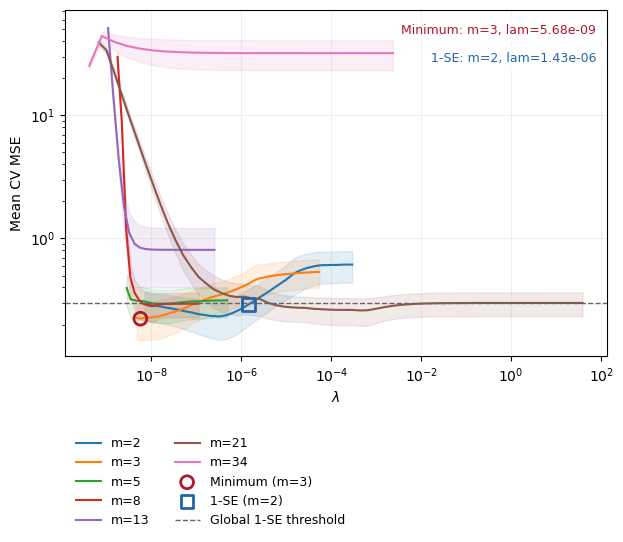

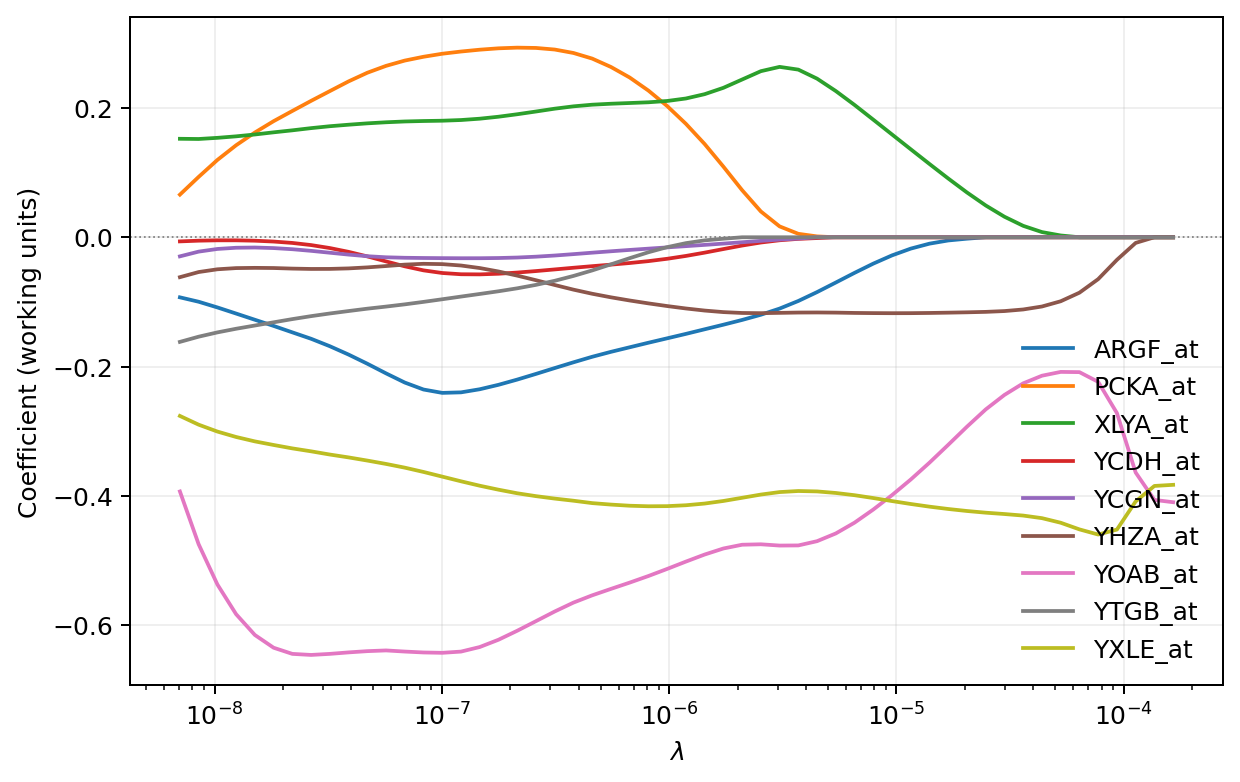

In [ ]:
MS = (2, 3, 5, 8, 13, 21, 34)
cv_by_m = {}
for m in MS:
    cv_by_m[m] = cv_fridge(X, y, ms=[m], lambdas=None, n_steps=100,
        n_folds=N_FOLDS, random_state=RANDOM_STATE, method="smooth",
        selection="1se", ridge_init=1e-6/(n*m), **PATH_OPTIONS)
    print(f"CV complete for m={m}")

# Combine the per-m searches under one global one-SE threshold.
records = {m: fit.results_[m] for m, fit in cv_by_m.items()}
best_error, best_m, best_index = min((float(r["mean_mse"][i]), m, i)
    for m, r in records.items() for i in range(len(r["lambdas"])))
one_se_threshold = best_error + records[best_m]["se_mse"][best_index]
one_m = next(m for m in sorted(records) if np.any(records[m]["mean_mse"] <= one_se_threshold))
valid = np.flatnonzero(records[one_m]["mean_mse"] <= one_se_threshold)
one_index = int(valid[np.argmax(records[one_m]["lambdas"][valid])])
one_lam = float(records[one_m]["lambdas"][one_index])

# Refit the global CV choice using a 100-interval full-data path.
cv_grid = records[one_m]["lambdas"]
selected_grid = (np.geomspace(cv_grid[0], cv_grid[-1], 101)
                 if len(cv_grid)>1 else cv_grid.copy())
selected_grid = np.unique(np.append(selected_grid, one_lam))
SELECTED_M, SELECTED_LAM = one_m, one_lam
selected_path = path_fridge(X, y, m=SELECTED_M, lambdas=selected_grid,
    ridge_init=1e-6/(n*SELECTED_M), **PATH_OPTIONS)
selected_index = int(np.flatnonzero(selected_path.lambdas_ == SELECTED_LAM)[0])
selected_fit = replace(cv_by_m[one_m].fit_, lam=one_lam,
    coef_=selected_path.coef_path_[selected_index].copy(),
    scaled_coef_=selected_path.scaled_coef_path_[selected_index].copy(),
    intercept_=float(selected_path.intercepts_[selected_index]),
    n_iter_=int(selected_path.n_iter_[selected_index]),
    converged_=bool(selected_path.converged_[selected_index]),
    kkt_residual_=float(selected_path.kkt_residuals_[selected_index]),
    objective_history_=np.array([selected_path.objectives_[selected_index]]))
fresh_cv = FridgeCV(records, best_m, float(records[best_m]["lambdas"][best_index]),
    one_m, one_lam, float(one_se_threshold), "1se", selected_fit,
    method="smooth", path_=selected_path)
fridge_beta = selected_fit.coef_.copy()

print("Minimum CV MSE:", best_error)
print("CV one-SE choice:", SELECTED_M, SELECTED_LAM)
print("CV-selected nonzeros:", np.count_nonzero(fridge_beta))
print("KKT residual:", selected_fit.kkt_residual_)
print("Converged:", selected_fit.converged_)
cv_ax = plot_cv_fridge(fresh_cv)
cv_ax.set_yscale("log")
plt.show()
plot_path_fridge(selected_path, feature_names=genes,
    features=np.flatnonzero(fridge_beta != 0), legend=True)
plt.show()


## Comparison methods

Adaptive Lasso uses a cross-validated ridge pilot and cross-validated weighted L1 fit. SCAD uses R `ncvreg` with ten folds and seed 0. SuSiE is fitted with at most 34 effects.

In [4]:
pilot = RidgeCV(cv=5).fit(X, y)
weights = 1/(np.abs(pilot.coef_)+1e-8)

adaptive = LassoCV(cv=N_FOLDS, random_state=42).fit(X/weights, y)
adalasso_beta = adaptive.coef_/weights

susie_fit = pysusie.susie(X, y, L=34)
pip = np.asarray(susie_fit.pip)
raw_sets = susie_fit.sets.get("cs", [])
if isinstance(raw_sets, dict):
    raw_sets = list(raw_sets.values())

credible_sets = [np.asarray(indices, dtype=int) for indices in raw_sets]
assert pip.shape == (p,) and np.all((pip >= 0) & (pip <= 1))

with TemporaryDirectory() as temporary:
    folder = Path(temporary)
    pd.DataFrame(X, columns=genes).to_csv(folder/"X.csv", index=False)
    pd.DataFrame({"y": y}).to_csv(folder/"y.csv", index=False)
    
    r_code = r"""
    args <- commandArgs(trailingOnly=TRUE); folder <- args[1]
    if (!requireNamespace("ncvreg", quietly=TRUE)) stop("Install R package ncvreg.")
    X <- as.matrix(read.csv(file.path(folder,"X.csv"),check.names=FALSE))
    y <- read.csv(file.path(folder,"y.csv"))$y
    set.seed(0)
    fit <- ncvreg::cv.ncvreg(X,y,family="gaussian",penalty="SCAD",nfolds=10)
    write.csv(data.frame(gene=colnames(X),beta=as.numeric(coef(fit))[-1]),
              file.path(folder,"scad.csv"),row.names=FALSE)
    """
    subprocess.run([R_SCRIPT,"--vanilla","-e",r_code,str(folder)],check=True)
    scad = pd.read_csv(folder/"scad.csv").set_index("gene").loc[genes]

scad_beta = scad.beta.to_numpy()

During startup - Warning message:
Setting LC_CTYPE failed, using "C" 


## SuSiE concordance and expression groups

Count the full nonzero set, overlap with the ten highest PIPs, overlap among the three leading coefficients, and credible-set membership. Group A is the empirical correlation group from the paper; group B is the reported five-gene SuSiE group. Recomputed credible sets are shown independently.

,nonzero,in_top10,leading3_in_top10,in_credible_set,correlated_pairs
method,,,,,
Fridge,9,3,3,1,0
SCAD,16,3,2,1,0
Adaptive Lasso,53,5,1,3,4


Recomputed CS1: ['YXLC_at', 'YXLD_at', 'YXLE_at', 'YXLF_at', 'YXLG_at']
Group A Fridge representatives: ['XLYA_at']
Group B Fridge representatives: ['YXLE_at']


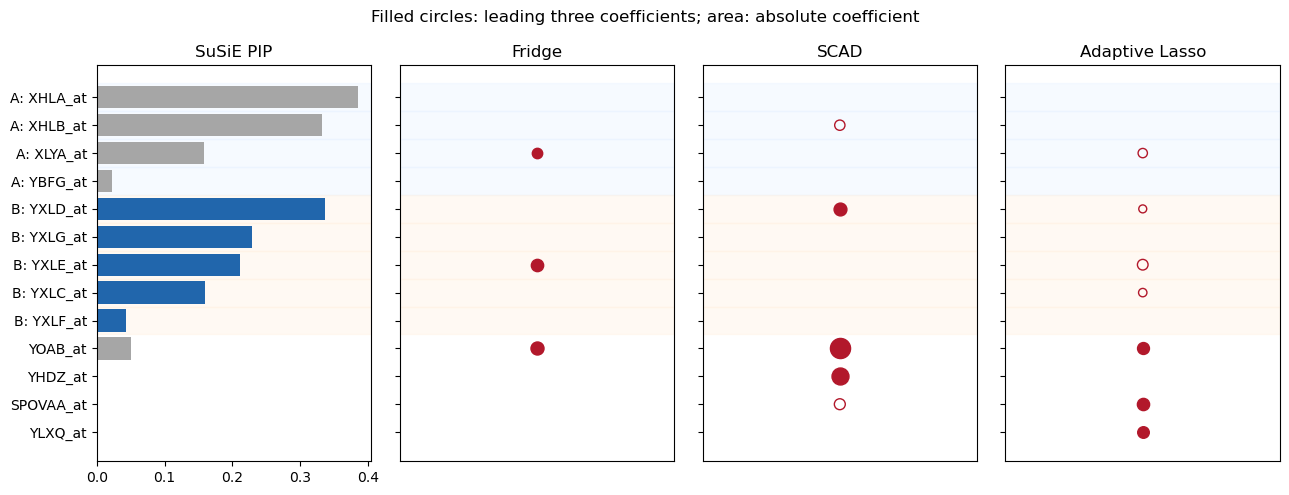

In [5]:
methods = {"Fridge": fridge_beta, "SCAD": scad_beta, "Adaptive Lasso": adalasso_beta}

top_pip = set(np.argsort(-pip, kind="stable")[:10])
cs_union = set(np.concatenate(credible_sets).tolist()) if credible_sets else set()

rows = []
for name, beta in methods.items():
    nonzero = np.flatnonzero(beta != 0)
    leading = np.argsort(-np.abs(beta), kind="stable")[:min(3,len(nonzero))]
    corr = np.corrcoef(X[:,nonzero], rowvar=False) if len(nonzero)>1 else np.zeros((1,1))
    rows.append(dict(method=name, nonzero=len(nonzero), in_top10=len(set(nonzero)&top_pip),
                     leading3_in_top10=len(set(leading)&top_pip),
                     in_credible_set=len(set(nonzero)&cs_union),
                     correlated_pairs=int(np.sum(np.triu(np.abs(corr)>0.9,1)))))

summary = pd.DataFrame(rows).set_index("method")
display(summary)

for i, members in enumerate(credible_sets, 1):
    print(f"Recomputed CS{i}:", list(genes[members]))

group_A = ["XHLA_at","XHLB_at","XLYA_at","YBFG_at"]
group_B = ["YXLC_at","YXLD_at","YXLE_at","YXLF_at","YXLG_at"]
for name, group in [("A",group_A),("B",group_B)]:
    indices = np.array([np.flatnonzero(genes==g)[0] for g in group])
    print(f"Group {name} Fridge representatives:", list(genes[indices[fridge_beta[indices]!=0]]))

shown = top_pip | cs_union
for beta in methods.values():
    shown |= set(np.argsort(-np.abs(beta),kind="stable")[:3])

shown = sorted(shown,key=lambda j: (0 if genes[j] in group_A else 1 if genes[j] in group_B else 2,-pip[j]))

fig, axes = plt.subplots(1,4,figsize=(13,max(5,len(shown)*.3)),sharey=True)
positions = np.arange(len(shown))
labels = [("A: " if genes[j] in group_A else "B: " if genes[j] in group_B else "")+genes[j] for j in shown]
axes[0].barh(positions,pip[shown],color=["#2166ac" if j in cs_union else "0.65" for j in shown])
axes[0].set_yticks(positions,labels); axes[0].invert_yaxis();axes[0].set_title("SuSiE PIP")
maximum = max(np.max(np.abs(beta[shown])) for beta in methods.values())

for ax,(name,beta) in zip(axes[1:],methods.items()):
    leading=set(np.argsort(-np.abs(beta),kind="stable")[:3])
    for row,j in enumerate(shown):
        if beta[j]!=0:
            ax.scatter(0,row,s=30+180*abs(beta[j])/maximum,
                       facecolors="#b2182b" if j in leading else "none",edgecolors="#b2182b")
    ax.set_title(name);ax.set_xticks([]);ax.set_xlim(-1,1)

for ax in axes:
    for row,j in enumerate(shown):
        if genes[j] in group_A:ax.axhspan(row-.5,row+.5,color="#e6f2ff",alpha=.35,zorder=-1)
        elif genes[j] in group_B:ax.axhspan(row-.5,row+.5,color="#fff0df",alpha=.35,zorder=-1)

fig.suptitle("Filled circles: leading three coefficients; area: absolute coefficient")
fig.tight_layout();plt.show()

## Bootstrap at the CV-selected tuning

Use 500 resamples to distinguish gene selection from selection of any member of group B. Hold the full-data CV-selected m, lambda, and path grid fixed; re-estimate adaptive weights within each resample. CV is not repeated inside the bootstrap. Set RUN_BOOTSTRAP=False above to skip this section.


In [ ]:
if RUN_BOOTSTRAP:
    rng = np.random.default_rng(RANDOM_STATE)
    bootstrap = np.empty((N_BOOTSTRAP,p))
    for draw in range(N_BOOTSTRAP):
        rows = rng.integers(0,n,size=n)
        fitted = path_fridge(X[rows],y[rows],m=SELECTED_M,lambdas=selected_grid,
                            ridge_init=1e-6/(n*SELECTED_M),**PATH_OPTIONS)
        bootstrap[draw] = fitted.coef_path_[selected_index]
        
        if (draw+1)%25==0:
            print(f"Bootstrap {draw+1}/{N_BOOTSTRAP}")
    
    indices = np.array([np.flatnonzero(genes==g)[0] for g in group_B])
    print("Selection of any group-B member:",np.mean(np.any(bootstrap[:,indices]!=0,axis=1)))
    print("YXLE_at selection:",np.mean(bootstrap[:,np.flatnonzero(genes=='YXLE_at')[0]]!=0))
    display(pd.DataFrame(dict(gene=genes,beta=fridge_beta,bootstrap_sd=bootstrap.std(axis=0),
                             selection_frequency=np.mean(bootstrap!=0,axis=0))).loc[fridge_beta!=0])

Bootstrap 25/500


Bootstrap 50/500


Bootstrap 75/500


Bootstrap 100/500


Bootstrap 125/500


...

Bootstrap 425/500


Bootstrap 450/500


Bootstrap 475/500


Bootstrap 500/500
Selection of any group-B member: 0.976
YXLE_at selection: 0.582


,gene,beta,bootstrap_sd,selection_frequency
72,ARGF_at,-0.142411,0.094272,0.584
791,PCKA_at,0.144298,0.112150,0.256
1302,XLYA_at,0.221436,0.119628,0.598
1477,YCDH_at,-0.023794,0.080231,0.436
1501,YCGN_at,-0.011803,0.091164,0.354
2094,YHZA_at,-0.113420,0.084932,0.684
2563,YOAB_at,-0.490978,0.145755,0.066
3310,YTGB_at,-0.004833,0.098327,0.340
4003,YXLE_at,-0.412081,0.198900,0.582


In [ ]:
import importlib.metadata

versions = {}
for package in ["pyfridge","numpy","scipy","pandas","scikit-learn","matplotlib","pysusie"]:
    try:
        versions[package]=importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        versions[package]="source checkout"

print(json.dumps(
    dict(data_url=DATA_URL,data_sha256=data_sha256,versions=versions,
                     selected_m=SELECTED_M,selected_normalized_lam=SELECTED_LAM,
                     bootstrap_draws=N_BOOTSTRAP if RUN_BOOTSTRAP else 0),
    indent=2
))


{
  "data_url": "https://raw.githubusercontent.com/cran/hdi/master/data/riboflavin.RData",
  "data_sha256": "ff5c2257a46367992cfb329041ffb5fef77663761811fef8c55043c274d8d2c5",
  "versions": {
    "pyfridge": "source checkout",
    "numpy": "2.2.6",
    "scipy": "1.16.1",
    "pandas": "2.3.2",
    "scikit-learn": "1.7.1",
    "matplotlib": "3.10.6",
    "pysusie": "0.1.0"
  },
  "selected_m": 2,
  "selected_normalized_lam": 1.4332712036147468e-06,
  "bootstrap_draws": 500
}


## References

- Park, S. and Stefanski, L. A. *Fractional Ridge Regression*. [arXiv:2505.23925v3](https://arxiv.org/html/2505.23925v3).
- Dataset: [CRAN hdi documentation](https://rdrr.io/cran/hdi/man/riboflavin.html), attributed to Bühlmann, Kalisch, and Meier (2014).
- Wang et al. (2020), *A simple new approach to variable selection in regression, with application to genetic fine mapping* (SuSiE).